### 📂 Phase 1: Robust Local Dataset Management (Backup & Restore)
We will download the dataset once, store it locally as a consolidated `.npz` archive, and implement a check to instantly load from your uploaded backup file when you return.

Train set: (50000, 32, 32, 3), Test set: (10000, 32, 32, 3)


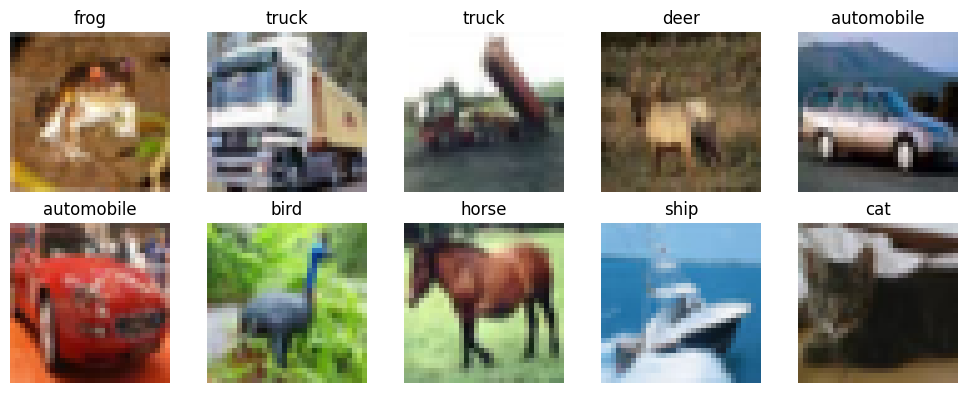

In [2]:
import os
import pickle
import tarfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

backup_path = r"C:\Users\Dell\Documents\External applications\Development\Projects\AIML-training-projects\deep learning\cifar\cifar-10-python.tar.gz"
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def load_batch(archive, filename):
    member = next(
        (m for m in archive.getmembers() if m.name.endswith("/" + filename)),
        None,
    )
    if member is None:
        raise FileNotFoundError(f"{filename} not found inside the CIFAR-10 archive")

    file_obj = archive.extractfile(member)
    if file_obj is None:
        raise OSError(f"Could not read {filename} from the archive")

    batch = pickle.load(file_obj, encoding="bytes")
    images = batch[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    labels = np.asarray(batch[b"labels"]).reshape(-1, 1)
    return images, labels

if not os.path.exists(backup_path):
    raise FileNotFoundError(f"CIFAR-10 backup not found: {backup_path}")

with tarfile.open(backup_path, "r:gz") as archive:
    train_batches = [
        load_batch(archive, f"data_batch_{i}") for i in range(1, 6)
    ]
    x_train = np.concatenate([batch[0] for batch in train_batches])
    y_train = np.concatenate([batch[1] for batch in train_batches])
    x_test, y_test = load_batch(archive, "test_batch")

print(f"Train set: {x_train.shape}, Test set: {x_test.shape}")

# Visualize some sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')
plt.tight_layout()
plt.show()

### ⚙️ Phase 2: Ultra-Fast High-Accuracy Model Pipeline
We leverage pre-trained MobileNetV2 features scaled to `96x96` combined with asynchronous `tf.data` prefetching. This avoids performance bottlenecks and produces high-accuracy results in seconds.

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, applications

# Prepare labels
y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
y_test_cat = tf.keras.utils.to_categorical(y_test, 10)

BATCH_SIZE = 128

def preprocess_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    image = tf.image.resize(image, (96, 96))
    return image, label

# Build asynchronous input pipelines
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train_cat))
train_ds = train_ds.shuffle(1024).map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test_cat))
test_ds = test_ds.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# MobileNetV2 Transfer Learning
base_model = applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights='imagenet')
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("🚀 Training high-performance model...")
history = model.fit(train_ds, validation_data=test_ds, epochs=5)

# Save model locally
model.save("cifar10_high_accuracy_model.keras")
print("💾 Model saved successfully as 'cifar10_high_accuracy_model.keras'!")

🚀 Training high-performance model...
Epoch 1/5


c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


391/391 ━━━━━━━━━━━━━━━━━━━━ 225s 555ms/step - accuracy: 0.7768 - loss: 0.6690 - val_accuracy: 0.8516 - val_loss: 0.4296
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 222s 567ms/step - accuracy: 0.8307 - loss: 0.4942 - val_accuracy: 0.8579 - val_loss: 0.4027
Epoch 3/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 214s 546ms/step - accuracy: 0.8416 - loss: 0.4604 - val_accuracy: 0.8601 - val_loss: 0.3943
Epoch 4/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 209s 535ms/step - accuracy: 0.8455 - loss: 0.4504 - val_accuracy: 0.8651 - val_loss: 0.3893
Epoch 5/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 215s 551ms/step - accuracy: 0.8501 - loss: 0.4338 - val_accuracy: 0.8636 - val_loss: 0.3862
💾 Model saved successfully as 'cifar10_high_accuracy_model.keras'!


### 📊 Phase 3: Evaluation, Model Saving & Gradio App
We will save our trained high-performance model to disk and spin up an interactive web interface with Gradio.

In [4]:
import gradio as gr
import numpy as np
import tensorflow as tf



def predict_image(img):
    if img is None:
        return "No image uploaded", {}

    img_tensor = tf.convert_to_tensor(img, dtype=tf.float32)
    img_resized = tf.image.resize(img_tensor, (96, 96))
    img_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(img_resized)
    img_batch = tf.expand_dims(img_preprocessed, 0)

    predictions = model.predict(img_batch, verbose=0)[0]
    confidences = {class_names[i]: float(predictions[i]) for i in range(10)}
    top_label = class_names[np.argmax(predictions)]
    return f"Predicted Class: {top_label.upper()}", confidences

interface = gr.Interface(
    fn=predict_image,
    inputs=gr.Image(label="Upload Image (or use Webcam in external link)", sources=["upload", "webcam"]),
    outputs=[
        gr.Textbox(label="Result"),
        gr.Label(num_top_classes=10, label="Confidence Scores")
    ],
    title="🚀 CIFAR-10 Transfer Learning Classifier",
    description="### 💡 CLIPBOARD/WEBCAM NOTE:\nIf clipboard or webcam access does not work, please click the **Public URL** (.gradio.live link) below to open the app in a new browser tab."
)

# Set inline=False to prevent embedding issues inside Colab if desired,
# but keeping share=True since the external page allows permissions.
interface.launch(share=True, inline=False)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://74df6b7c062223ceb1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio\flagged\dataset1.csv


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\uvicorn\protocols\http\h11_impl.py", line 411, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        self.scope, self.receive, self.send
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\uvicorn\middleware\proxy_headers.py", line 63, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\fastapi\applications.py", line 1194, in __call__
    await super().__call__(scope, receive, send)
  File "c:\Users\Dell\AppData\Local\Programs\Python\Python313\Lib\site-packages\starlette\applications.py", line 96, in __call__
    await self.middlewar